=== ANT COLONY LOGISTICS ROUTE OPTIMIZER ===
Enter number of Ants (Default 15): 15
Enter maximum iterations (Default 150): 150

Computing optimal path routes...

================== COMPUTATION RESULTS ==================
Optimal Total Distance: 17.20 km
Sequence: Warehouse Depot (0) ➔ Stop A (1) ➔ Stop C (3) ➔ Stop B (2) ➔ Warehouse Depot (0)

[System] Opening visual map window... Close the window to exit program.


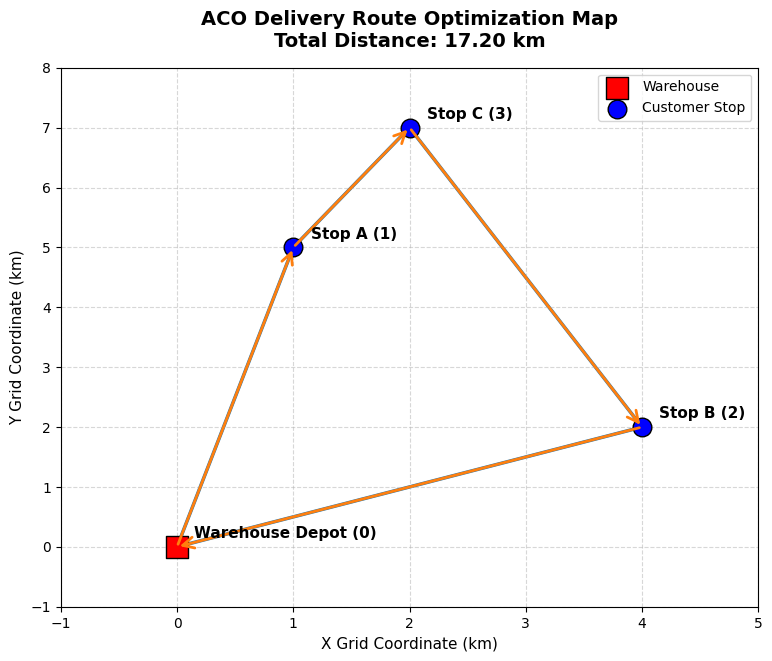

In [7]:
import numpy as np
import random
import time
import matplotlib.pyplot as plt

class AntColonyOptimizer:
    def __init__(self, distances, n_ants, n_best, n_iterations, decay, alpha=1, beta=2, Q=100):
        self.distances = distances
        self.pheromone = np.ones(self.distances.shape) / len(distances)
        self.all_inds = range(len(distances))
        self.n_ants = n_ants
        self.n_best = n_best
        self.n_iterations = n_iterations
        self.decay = decay
        self.alpha = alpha
        self.beta = beta
        self.Q = Q

    def run(self):
        shortest_path = None
        all_time_shortest_path = ("placeholder", np.inf)

        for i in range(self.n_iterations):
            all_paths = self.gen_all_paths()
            self.spread_pheromone(all_paths, self.n_best)
            shortest_path = min(all_paths, key=lambda x: x[1])

            if shortest_path[1] < all_time_shortest_path[1]:
                all_time_shortest_path = shortest_path
            self.pheromone = self.pheromone * self.decay
        return all_time_shortest_path

    def spread_pheromone(self, all_paths, n_best):
        sorted_paths = sorted(all_paths, key=lambda x: x[1])
        for path, dist in sorted_paths[:n_best]:
            for move in path:
                self.pheromone[move] += self.Q / dist

    def gen_path_dist(self, path):
        total_dist = 0
        for move in path:
            total_dist += self.distances[move]
        return total_dist

    def gen_all_paths(self):
        all_paths = []
        for i in range(self.n_ants):
            path = self.gen_path(0)
            all_paths.append((path, self.gen_path_dist(path)))
        return all_paths

    def gen_path(self, start):
        path = []
        visited = set()
        visited.add(start)
        prev = start
        for i in range(len(self.distances) - 1):
            move = self.pick_move(self.pheromone[prev], self.distances[prev], visited)
            path.append((prev, move))
            prev = move
            visited.add(move)
        path.append((prev, start))
        return path

    def pick_move(self, pheromone, dist, visited):
        pheromone = np.copy(pheromone)
        pheromone[list(visited)] = 0
        row = dist ** self.beta
        with np.errstate(divide='ignore'):
            row = 1.0 / row
        row[list(visited)] = 0
        norm_pheromone = pheromone ** self.alpha
        probabilities = norm_pheromone * row
        if probabilities.sum() == 0:
            return random.choice([i for i in self.all_inds if i not in visited])
        probabilities = probabilities / probabilities.sum()
        return np.random.choice(self.all_inds, p=probabilities)

def plot_route_map(coordinates, route_nodes, stop_names, total_distance):
    """Generates a high-quality visual GUI window for the delivery map"""
    plt.figure(figsize=(9, 7))

    # 1. Plot the delivery paths/edges
    for i in range(len(route_nodes) - 1):
        start_node = route_nodes[i]
        end_node = route_nodes[i+1]

        x_coords = [coordinates[start_node][0], coordinates[end_node][0]]
        y_coords = [coordinates[start_node][1], coordinates[end_node][1]]

        # Draw line with an arrow to show delivery direction flow
        plt.plot(x_coords, y_coords, color='#1f77b4', linestyle='-', linewidth=2.5, zorder=1)
        plt.annotate('', xy=(coordinates[end_node][0], coordinates[end_node][1]),
                     xytext=(coordinates[start_node][0], coordinates[start_node][1]),
                     arrowprops=dict(arrowstyle="->", color='#ff7f0e', lw=2, mutation_scale=20))

    # 2. Plot the Stops/Nodes
    for node_idx, (x, y) in coordinates.items():
        if node_idx == 0:
            # Highlight Warehouse distinctly
            plt.scatter(x, y, color='red', s=250, edgecolors='black', marker='s', label='Warehouse', zorder=2)
        else:
            plt.scatter(x, y, color='blue', s=180, edgecolors='black', marker='o', label='Customer Stop' if node_idx==1 else "", zorder=2)

        # Add text labels on the graph window
        plt.text(x + 0.15, y + 0.15, f"{stop_names[node_idx]} ({node_idx})", fontsize=11, fontweight='bold')

    # Styling and Map Details
    plt.title(f"ACO Delivery Route Optimization Map\nTotal Distance: {total_distance:.2f} km", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("X Grid Coordinate (km)", fontsize=11)
    plt.ylabel("Y Grid Coordinate (km)", fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper right')

    # Give layout breathing room
    plt.xlim(min([c[0] for c in coordinates.values()]) - 1, max([c[0] for c in coordinates.values()]) + 1)
    plt.ylim(min([c[1] for c in coordinates.values()]) - 1, max([c[1] for c in coordinates.values()]) + 1)

    print("\n[System] Opening visual map window... Close the window to exit program.")
    plt.show()

if __name__ == "__main__":
    print("=== ANT COLONY LOGISTICS ROUTE OPTIMIZER ===")

    # 1. INTERACTIVE PARAMETER INPUTS
    try:
        user_ants = int(input("Enter number of Ants (Default 15): ") or 15)
        user_iters = int(input("Enter maximum iterations (Default 150): ") or 150)
    except ValueError:
        print("Invalid entry, utilizing default settings...")
        user_ants, user_iters = 15, 150

    stop_names = {0: "Warehouse Depot", 1: "Stop A", 2: "Stop B", 3: "Stop C"}
    coordinates = {0: (0, 0), 1: (1, 5), 2: (4, 2), 3: (2, 7)}

    distance_matrix = np.array([
        [0.00, 5.10, 4.47, 7.28],
        [5.10, 0.00, 4.24, 2.24],
        [4.47, 4.24, 0.00, 5.39],
        [7.28, 2.24, 5.39, 0.00]
    ])

    print("\nComputing optimal path routes...")

    # 2. RUN ALGORITHM
    aco = AntColonyOptimizer(distance_matrix, n_ants=user_ants, n_best=3, n_iterations=user_iters, decay=0.95)
    best_edges, shortest_distance = aco.run()

    # Reconstruct the sequence loop
    route_nodes = [0]
    current = 0
    temp_edges = list(best_edges)
    while temp_edges:
        for edge in temp_edges:
            if edge[0] == current:
                route_nodes.append(edge[1])
                current = edge[1]
                temp_edges.remove(edge)
                break

    print("\n================== COMPUTATION RESULTS ==================")
    print(f"Optimal Total Distance: {shortest_distance:.2f} km")
    print("Sequence: " + " ➔ ".join([f"{stop_names[n]} ({n})" for n in route_nodes]))
    print("=========================================================")

    # 3. TRIGGER VISUAL GUI MAP WINDOW
    plot_route_map(coordinates, route_nodes, stop_names, shortest_distance)
